# Time Series Case Study: Renewable Energy Generation - North Zone (India)


## Problem Statement

India's electricity grid is undergoing a rapid shift toward renewable generation, but the share of renewables in the mix varies hour to hour depending on solar availability, demand, and dispatch decisions. Before any forecasting or grid-planning model can be built, we need to understand how this renewable share behaves over time — whether it trends, how strongly it follows a daily cycle, and what needs to be done to it to make it stationary.

This case study examines the **North zone (IN-NO)** of the Indian grid using hourly renewable-energy-percentage data from January to August 2026. The research question is:

> **Does the North zone's renewable energy share exhibit a trend and a stable daily seasonal pattern, and what differencing is required to make the series stationary for time-series modelling (e.g. SARIMA)?**

Specifically, this notebook investigates:
- Is the raw series stationary, or does it carry a trend and/or a seasonal unit root?
- What is the shape and strength of the daily (24-hour) seasonal cycle in renewable generation?
- What combination of non-seasonal (d) and seasonal (D, s) differencing is needed to achieve stationarity?

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("long_north.csv")
df.head()

,datetime,zone,renewable_energy_percent,is_estimated
0,2026-01-01 00:00:00+00:00,IN-NO,13,False
1,2026-01-01 01:00:00+00:00,IN-NO,19,False
2,2026-01-01 02:00:00+00:00,IN-NO,25,False
3,2026-01-01 03:00:00+00:00,IN-NO,31,False
4,2026-01-01 04:00:00+00:00,IN-NO,34,False


In [2]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5832 entries, 0 to 5831
Data columns (total 4 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   datetime                  5832 non-null   object
 1   zone                      5832 non-null   object
 2   renewable_energy_percent  5832 non-null   int64 
 3   is_estimated              5832 non-null   bool  
dtypes: bool(1), int64(1), object(2)
memory usage: 142.5+ KB


In [3]:
df.describe(include="all")

,datetime,zone,renewable_energy_percent,is_estimated
count,5832,5832,5832.000000,5832
unique,5832,1,NaN,2
top,2026-08-31 23:00:00+00:00,IN-NO,NaN,False
freq,1,5832,NaN,5784
mean,NaN,NaN,34.876543,NaN
std,NaN,NaN,14.666060,NaN
min,NaN,NaN,9.000000,NaN
25%,NaN,NaN,23.000000,NaN
50%,NaN,NaN,33.000000,NaN
75%,NaN,NaN,49.000000,NaN


In [4]:
print("Zones present:", df['zone'].unique())
print("Estimated vs observed counts:")
print(df['is_estimated'].value_counts())
print("Missing values per column:")
print(df.isna().sum())

Zones present: ['IN-NO']
Estimated vs observed counts:
is_estimated
False    5784
True       48
Name: count, dtype: int64
Missing values per column:
datetime                    0
zone                        0
renewable_energy_percent    0
is_estimated                0
dtype: int64


In [5]:
df["datetime"] = pd.to_datetime(df["datetime"])
df = df.sort_values("datetime").set_index("datetime")

ts = df["renewable_energy_percent"].dropna()

print("Number of observations:", len(ts))
print("Date range:", ts.index.min(), "to", ts.index.max())
print("Sampling frequency (most common gap):")
print(df.index.to_series().diff().value_counts().head(5))

Number of observations: 5832
Date range: 2026-01-01 00:00:00+00:00 to 2026-08-31 23:00:00+00:00
Sampling frequency (most common gap):
datetime
0 days 01:00:00    5831
Name: count, dtype: int64


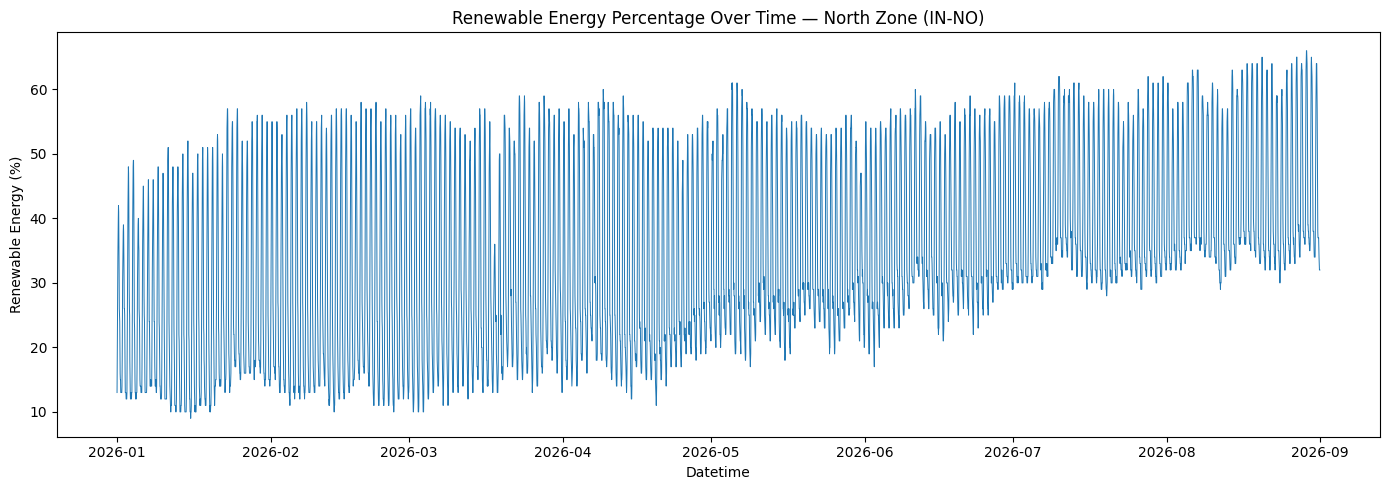

In [6]:
plt.figure(figsize=(14, 5))
plt.plot(ts, linewidth=0.7)
plt.title("Renewable Energy Percentage Over Time — North Zone (IN-NO)")
plt.xlabel("Datetime")
plt.ylabel("Renewable Energy (%)")
plt.tight_layout()
plt.show()

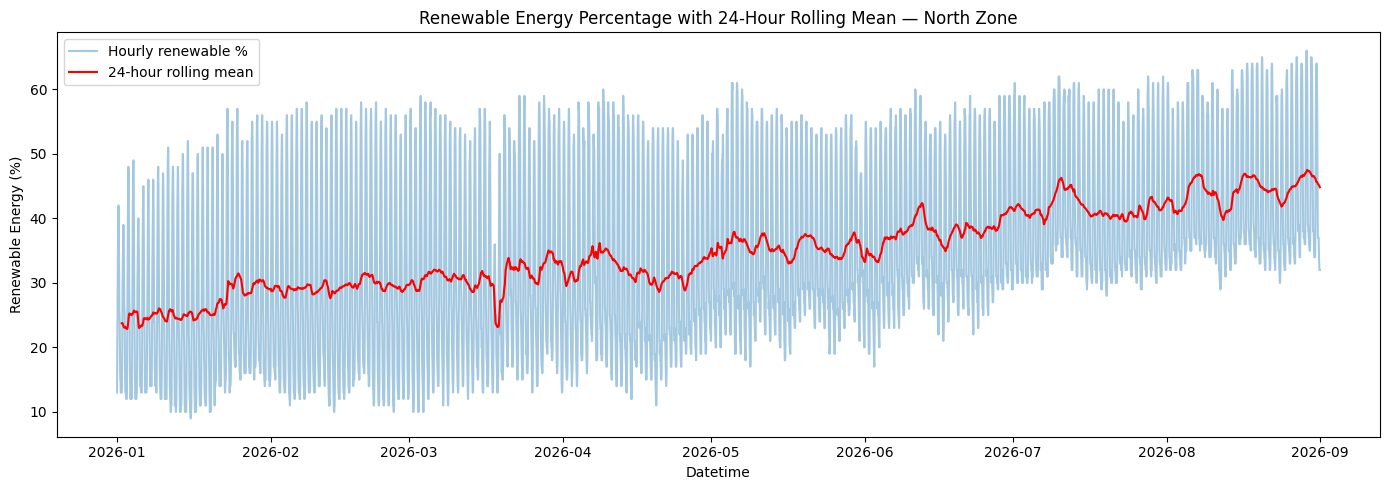

In [7]:
rolling_mean = ts.rolling(window=24).mean()

plt.figure(figsize=(14, 5))
plt.plot(ts, alpha=0.4, label="Hourly renewable %")
plt.plot(rolling_mean, color="red", label="24-hour rolling mean")
plt.title("Renewable Energy Percentage with 24-Hour Rolling Mean — North Zone")
plt.xlabel("Datetime")
plt.ylabel("Renewable Energy (%)")
plt.legend()
plt.tight_layout()
plt.show()

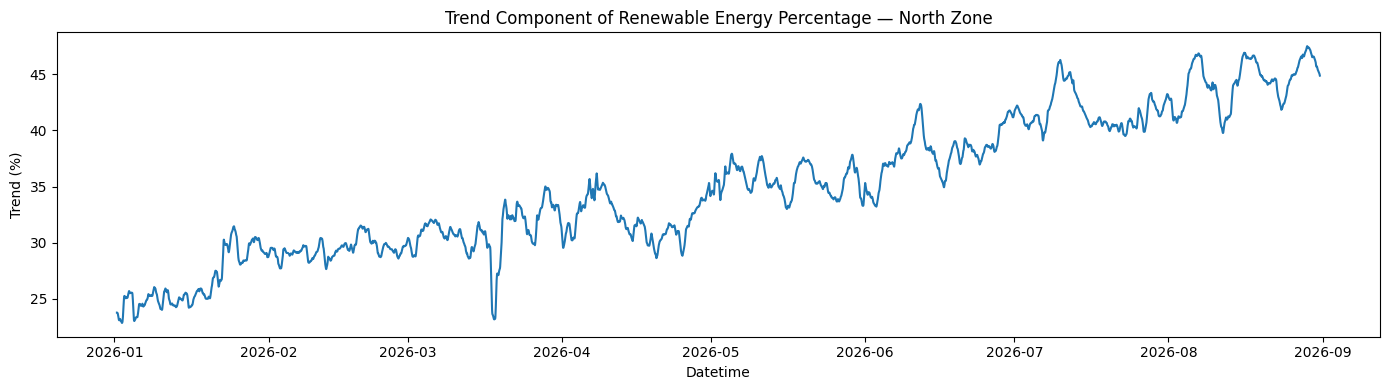

In [8]:
from statsmodels.tsa.seasonal import seasonal_decompose

decomposition = seasonal_decompose(ts, model="additive", period=24)  # daily seasonality (24 hourly obs/day)

plt.figure(figsize=(14, 4))
plt.plot(decomposition.trend)
plt.title("Trend Component of Renewable Energy Percentage — North Zone")
plt.xlabel("Datetime")
plt.ylabel("Trend (%)")
plt.tight_layout()
plt.show()

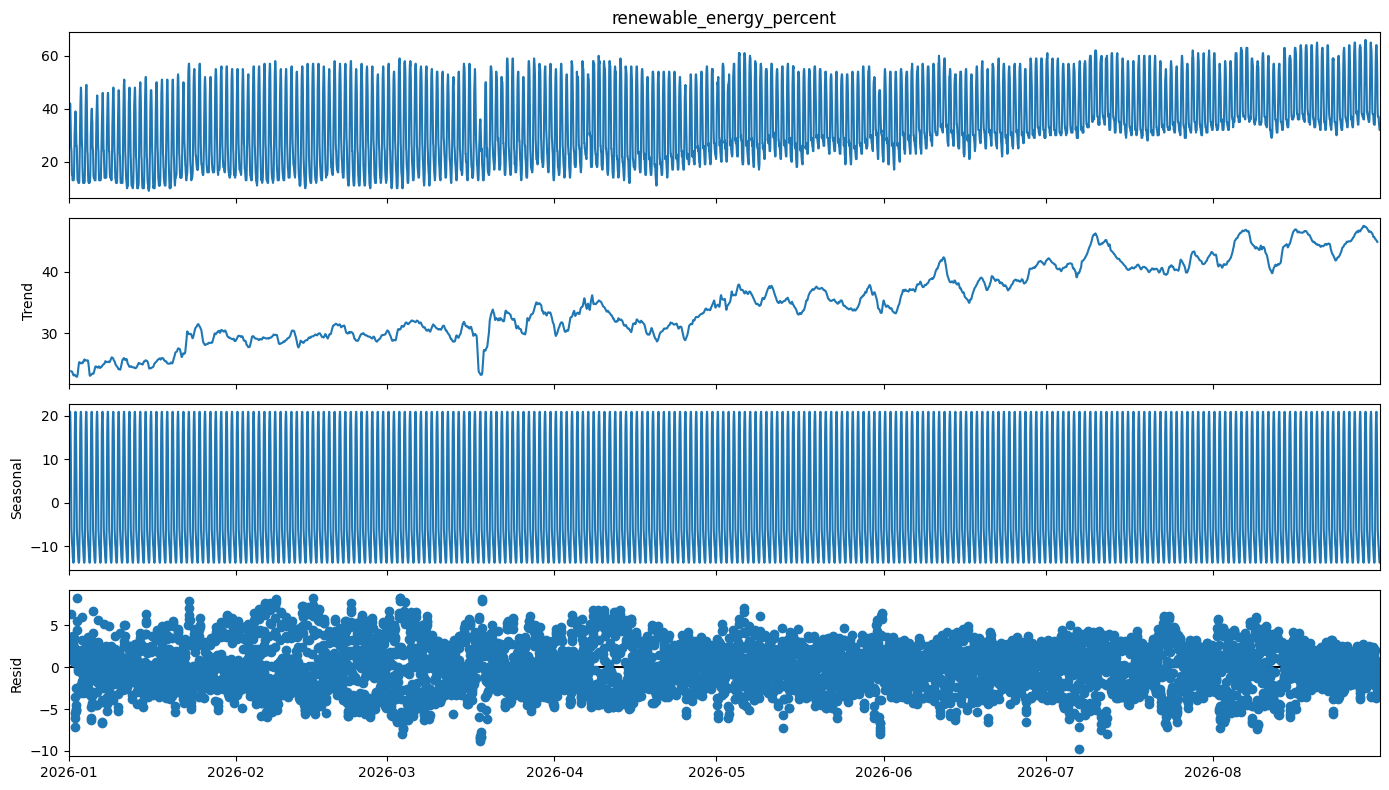

In [9]:
fig = decomposition.plot()
fig.set_size_inches(14, 8)
plt.tight_layout()
plt.show()

Trend: The trend gives us a smoother view of how the overall renewable share changes over time. Since we are using a 24-hour window, it smooths out the daily fluctuations and helps us see the underlying month-to-month movement in the data.

Seasonal: The seasonal component represents the repeating 24-hour pattern in renewable energy generation. We can see renewable energy increasing during the morning and around midday as solar generation rises, and then decreasing through the evening and night. Since this is a classical seasonal decomposition with a period of 24, the same average daily pattern is repeated across the entire dataset.

Residual: The residual is what remains after removing the trend and seasonal pattern from the original data. It represents the shorter-term fluctuations that are not explained by the overall trend or the repeating daily cycle. These could include day-to-day changes caused by weather or other factors.

Overall interpretation: The trend shows that the renewable-energy percentage is not constant throughout the eight-month period. There is a noticeable change in the underlying level over time rather than the renewable share staying around one fixed average. At the same time, the data shows a clear and stable 24-hour seasonal pattern, which is consistent with the daily cycle of solar generation.

About the cyclic pattern: One important point is that the classical decomposition calculates an average 24-hour pattern and then repeats that same pattern for every day. So the seasonal component will naturally look very regular throughout the eight months. In this case, the daily pattern has one clear peak rather than multiple peaks. It reaches its lowest point around 22:00 UTC (about 03:30 IST), then rises through the morning and reaches its peak around 07:00 UTC (about 12:30 IST), before gradually falling again during the afternoon and evening. This overall shape is consistent with renewable generation following the daily solar cycle.

In [10]:
from statsmodels.tsa.stattools import adfuller

result = adfuller(ts)

print("ADF Statistic:", result[0])
print("p-value:", result[1])

if result[1] < 0.05:
    print("Conclusion: The series is stationary.")
else:
    print("Conclusion: The series is non-stationary.")

ADF Statistic: -1.9919722415795182
p-value: 0.2901040466210869
Conclusion: The series is non-stationary.


In [11]:
from statsmodels.tsa.stattools import kpss

kpss_stat, kpss_pvalue, kpss_lags, kpss_crit = kpss(ts, regression="c", nlags="auto")

print("KPSS Statistic:", kpss_stat)
print("p-value:", kpss_pvalue)
print("Critical values:", kpss_crit)

if kpss_pvalue < 0.05:
    print("Conclusion: The series is non-stationary .")
else:
    print("Conclusion: The series is stationary.")

KPSS Statistic: 12.36478880717541
p-value: 0.01
Critical values: {'10%': 0.347, '5%': 0.463, '2.5%': 0.574, '1%': 0.739}
Conclusion: The series is non-stationary .


C:\Users\ritha\AppData\Local\Temp\ipykernel_26040\1874323340.py:3: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is smaller than the p-value returned.

  kpss_stat, kpss_pvalue, kpss_lags, kpss_crit = kpss(ts, regression="c", nlags="auto")


In [12]:
# First-order differencing
ts_diff = ts.diff().dropna()

result_diff = adfuller(ts_diff)

print("ADF Statistic:", result_diff[0])
print("p-value:", result_diff[1])

if result_diff[1] < 0.05:
    print("Conclusion: The differenced series is stationary.")
else:
    print("Conclusion: The differenced series is non-stationary.")

ADF Statistic: -20.89404275730292
p-value: 0.0
Conclusion: The differenced series is stationary.


In [13]:
kpss_stat_diff, kpss_pvalue_diff, kpss_lags_diff, kpss_crit_diff = kpss(ts_diff, regression="c", nlags="auto")

print("KPSS Statistic:", kpss_stat_diff)
print("p-value:", kpss_pvalue_diff)
print("Critical values:", kpss_crit_diff)

if kpss_pvalue_diff < 0.05:
    print("Conclusion: The differenced series is non-stationary.")
else:
    print("Conclusion: The differenced series is stationary.")

KPSS Statistic: 0.008543788649522918
p-value: 0.1
Critical values: {'10%': 0.347, '5%': 0.463, '2.5%': 0.574, '1%': 0.739}
Conclusion: The differenced series is stationary.


C:\Users\ritha\AppData\Local\Temp\ipykernel_26040\79763056.py:1: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is greater than the p-value returned.

  kpss_stat_diff, kpss_pvalue_diff, kpss_lags_diff, kpss_crit_diff = kpss(ts_diff, regression="c", nlags="auto")


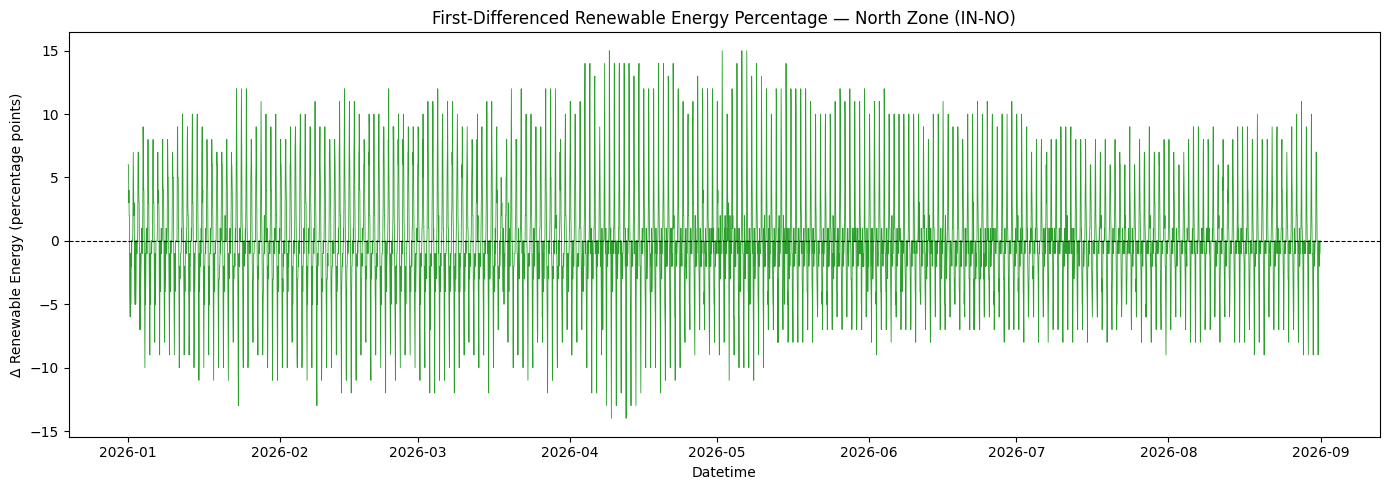

In [14]:
plt.figure(figsize=(14, 5))
plt.plot(ts_diff, linewidth=0.6, color="tab:green")
plt.axhline(0, color="black", linewidth=0.8, linestyle="--")
plt.title("First-Differenced Renewable Energy Percentage — North Zone (IN-NO)")
plt.xlabel("Datetime")
plt.ylabel("Δ Renewable Energy (percentage points)")
plt.tight_layout()
plt.show()

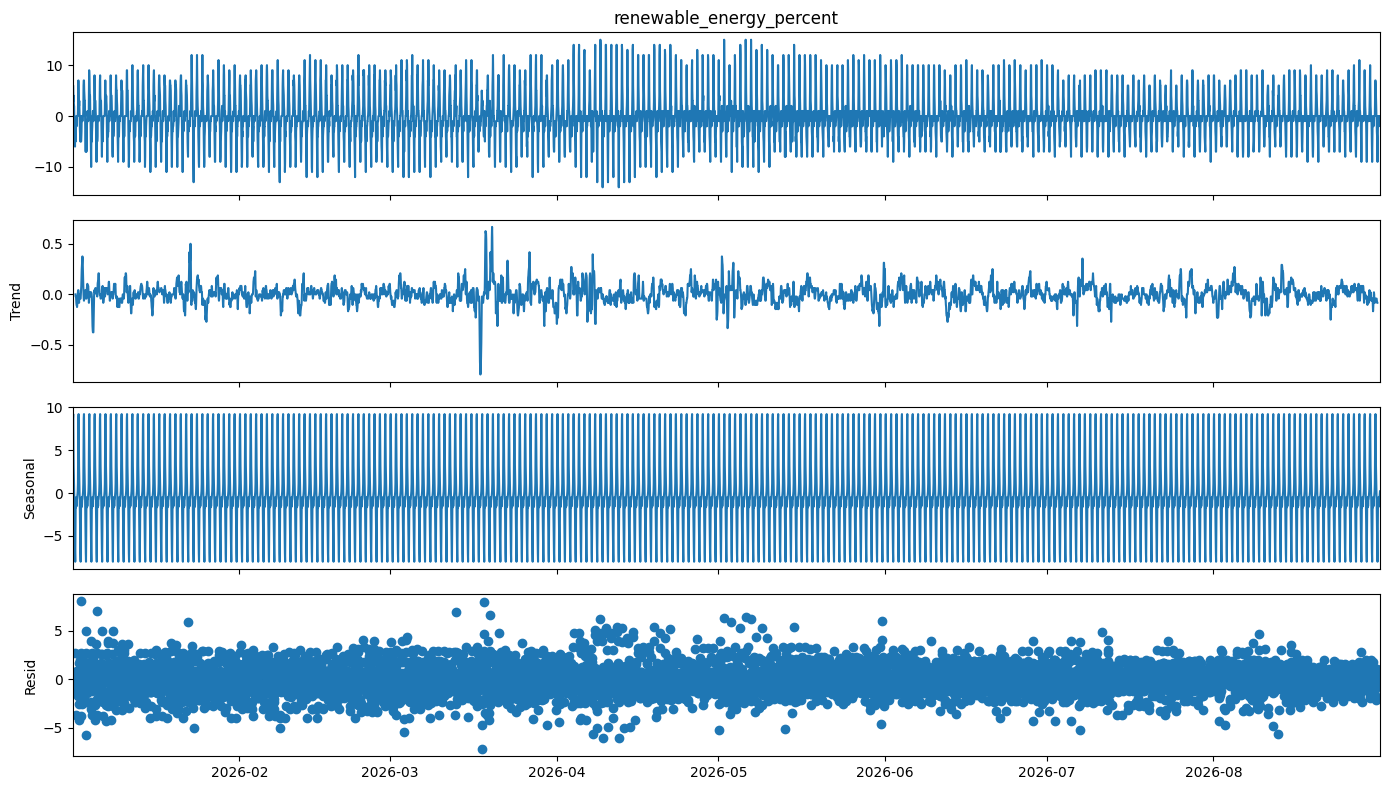

In [15]:
decomposition_diff = seasonal_decompose(ts_diff, model="additive", period=24)

fig = decomposition_diff.plot()
fig.set_size_inches(14, 8)
plt.tight_layout()
plt.show()

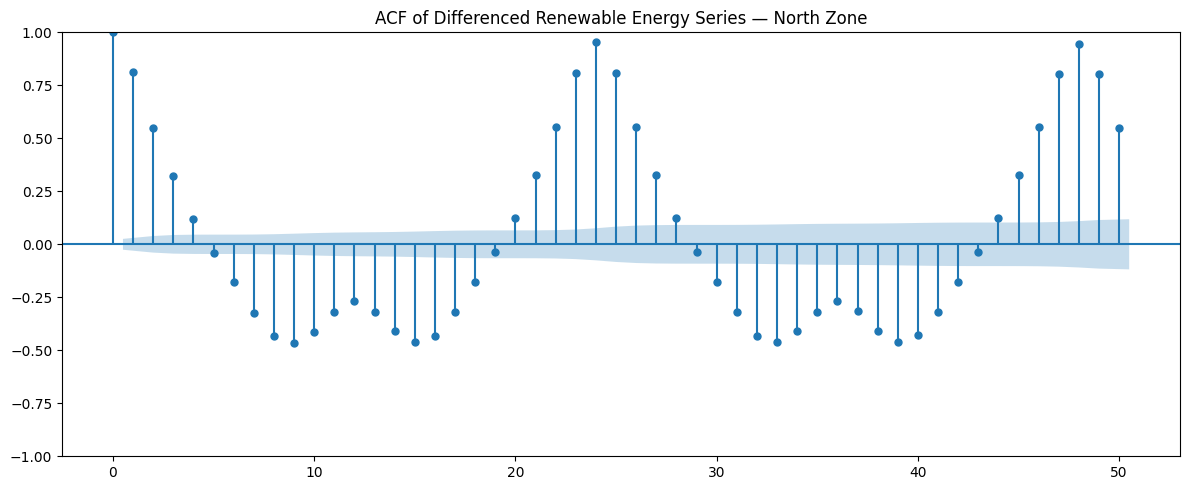

In [16]:
from statsmodels.graphics.tsaplots import plot_acf

plt.figure(figsize=(12, 5))
plot_acf(ts_diff, lags=50, ax=plt.gca())
plt.title("ACF of Differenced Renewable Energy Series — North Zone")
plt.tight_layout()
plt.show()

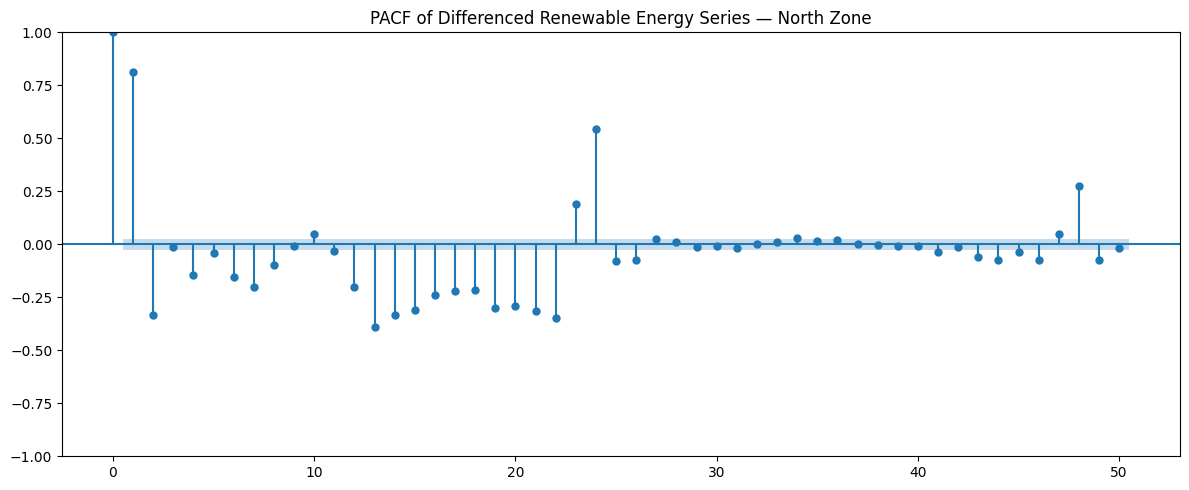

In [17]:
from statsmodels.graphics.tsaplots import plot_pacf

plt.figure(figsize=(12, 5))
plot_pacf(ts_diff, lags=50, method="ywm", ax=plt.gca())
plt.title("PACF of Differenced Renewable Energy Series — North Zone")
plt.tight_layout()
plt.show()

Based on the PACF plot, the p value can be taken as 1 because there is a strong spike at lag 1 followed by a reduction in the non-seasonal lags. From the ACF, q = 1 can be considered as an initial candidate. However, the ACF also shows strong repeating spikes at lag 24 and lag 48. Since the data is hourly, these correspond to 24-hour and 48-hour intervals, indicating a strong daily seasonal pattern.

In [18]:
from statsmodels.tsa.stattools import acf

acf_diff_long = acf(ts_diff, nlags=200)

print("ACF of the first-differenced series at multiples of 24:")
for k in range(1, 9):
    lag = 24 * k
    print(f"  lag {lag:4d}: {acf_diff_long[lag]: .4f}")

ACF of the first-differenced series at multiples of 24:
  lag   24:  0.9553
  lag   48:  0.9472
  lag   72:  0.9385
  lag   96:  0.9316
  lag  120:  0.9277
  lag  144:  0.9243
  lag  168:  0.9241
  lag  192:  0.9192


In [19]:
# Seasonal differencing (D = 1) at lag 24, applied on top of the first difference
ts_diff_seasonal = ts_diff.diff(24).dropna()

result_diff_seasonal = adfuller(ts_diff_seasonal)

print("ADF Statistic:", result_diff_seasonal[0])
print("p-value:", result_diff_seasonal[1])

if result_diff_seasonal[1] < 0.05:
    print("Conclusion: The seasonally differenced series is stationary.")
else:
    print("Conclusion: The seasonally differenced series is non-stationary.")

ADF Statistic: -21.65785161776198
p-value: 0.0
Conclusion: The seasonally differenced series is stationary.


In [20]:
kpss_stat_seasonal, kpss_pvalue_seasonal, kpss_lags_seasonal, kpss_crit_seasonal = kpss(ts_diff_seasonal, regression="c", nlags="auto")

print("KPSS Statistic:", kpss_stat_seasonal)
print("p-value:", kpss_pvalue_seasonal)
print("Critical values:", kpss_crit_seasonal)

if kpss_pvalue_seasonal < 0.05:
    print("Conclusion: The seasonally differenced series is non-stationary.")
else:
    print("Conclusion: The seasonally differenced series is stationary.")

KPSS Statistic: 0.008314768908643745
p-value: 0.1
Critical values: {'10%': 0.347, '5%': 0.463, '2.5%': 0.574, '1%': 0.739}
Conclusion: The seasonally differenced series is stationary.


C:\Users\ritha\AppData\Local\Temp\ipykernel_26040\2869048322.py:1: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is greater than the p-value returned.

  kpss_stat_seasonal, kpss_pvalue_seasonal, kpss_lags_seasonal, kpss_crit_seasonal = kpss(ts_diff_seasonal, regression="c", nlags="auto")


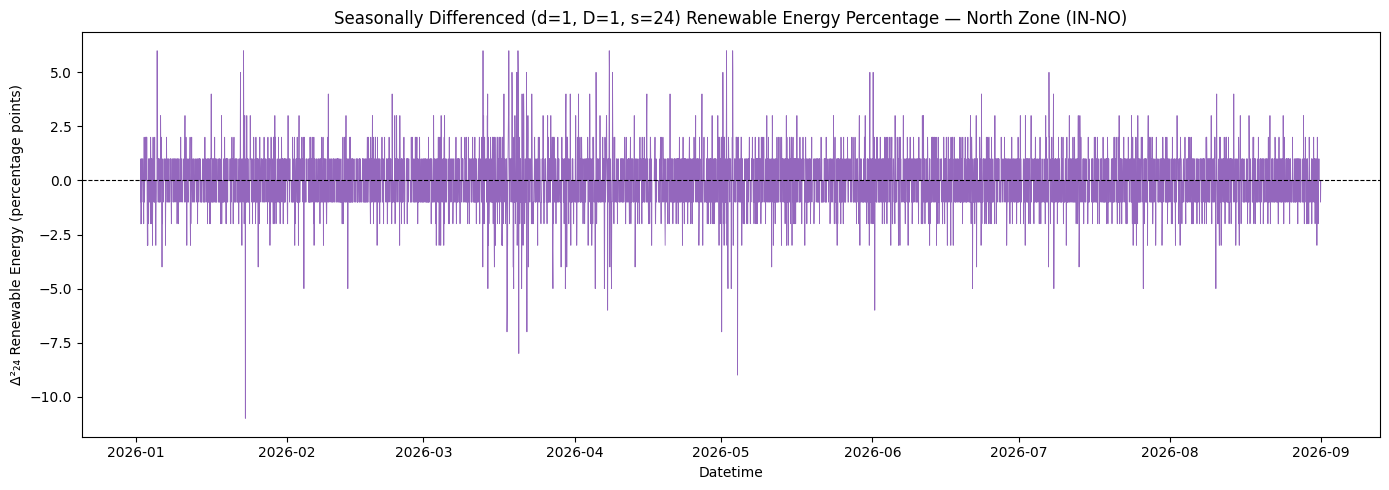

In [21]:
plt.figure(figsize=(14, 5))
plt.plot(ts_diff_seasonal, linewidth=0.6, color="tab:purple")
plt.axhline(0, color="black", linewidth=0.8, linestyle="--")
plt.title("Seasonally Differenced (d=1, D=1, s=24) Renewable Energy Percentage — North Zone (IN-NO)")
plt.xlabel("Datetime")
plt.ylabel("Δ²₂₄ Renewable Energy (percentage points)")
plt.tight_layout()
plt.show()

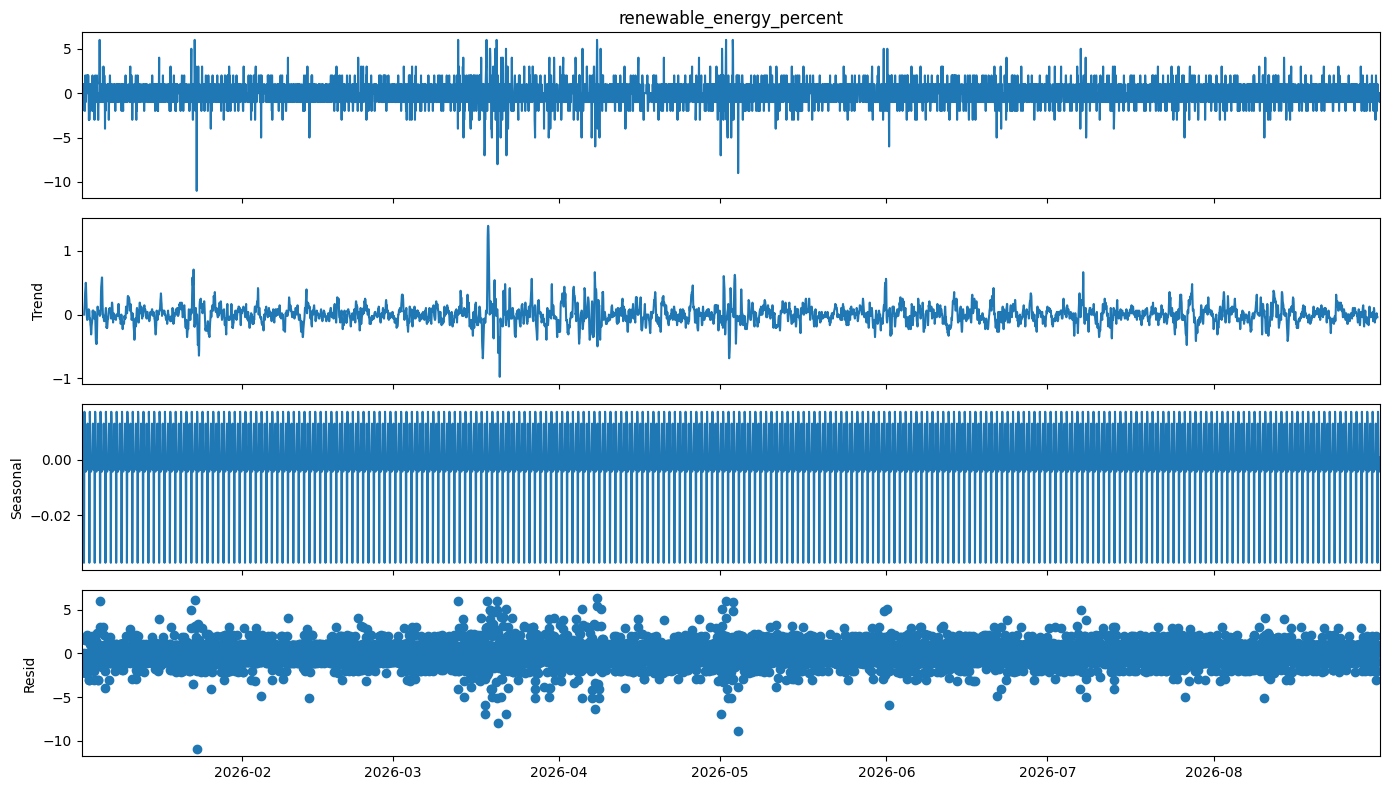

In [22]:
decomposition_diff_seasonal = seasonal_decompose(ts_diff_seasonal, model="additive", period=24)

fig = decomposition_diff_seasonal.plot()
fig.set_size_inches(14, 8)
plt.tight_layout()
plt.show()

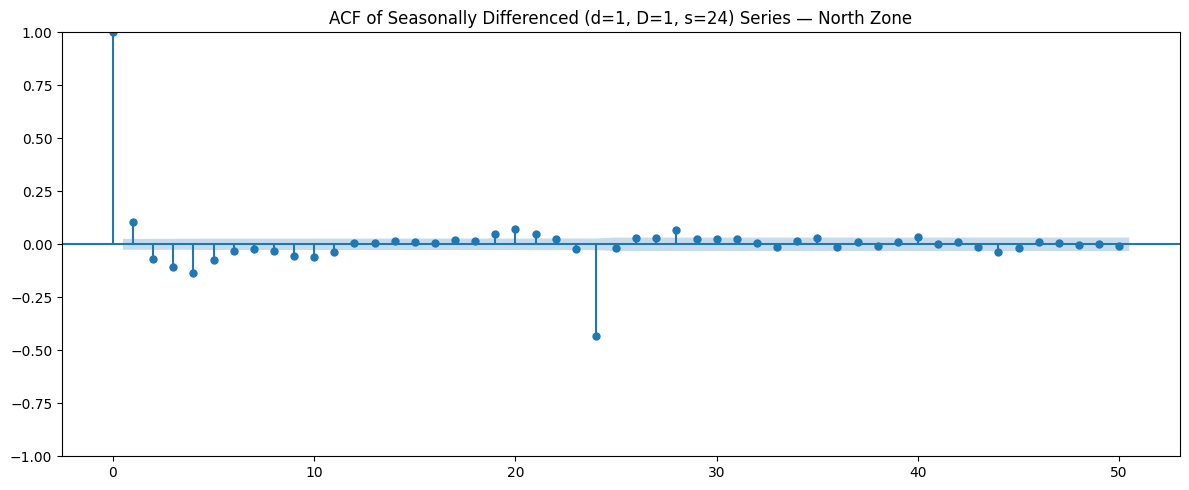

In [23]:
plt.figure(figsize=(12, 5))
plot_acf(ts_diff_seasonal, lags=50, ax=plt.gca())
plt.title("ACF of Seasonally Differenced (d=1, D=1, s=24) Series — North Zone")
plt.tight_layout()
plt.show()

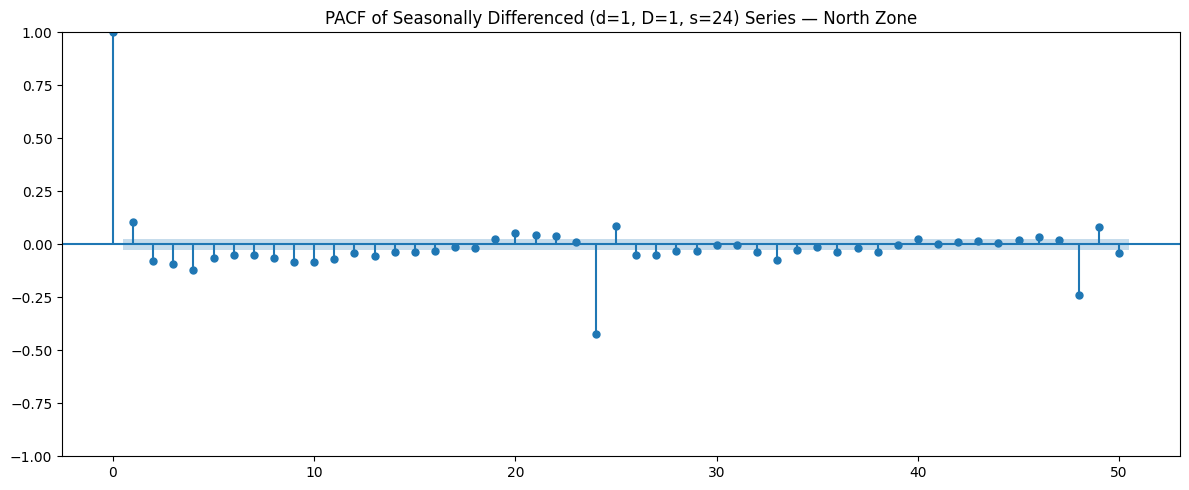

In [24]:
plt.figure(figsize=(12, 5))
plot_pacf(ts_diff_seasonal, lags=50, method="ywm", ax=plt.gca())
plt.title("PACF of Seasonally Differenced (d=1, D=1, s=24) Series — North Zone")
plt.tight_layout()
plt.show()

In [25]:
acf_diff_seasonal_long = acf(ts_diff_seasonal, nlags=200)

print("ACF of the (d=1, D=1, s=24) differenced series at multiples of 24:")
for k in range(1, 9):
    lag = 24 * k
    print(f"  lag {lag:4d}: {acf_diff_seasonal_long[lag]: .4f}")

ACF of the (d=1, D=1, s=24) differenced series at multiples of 24:
  lag   24: -0.4323
  lag   48: -0.0031
  lag   72: -0.0210
  lag   96: -0.0289
  lag  120: -0.0084
  lag  144: -0.0364
  lag  168:  0.0576
  lag  192:  0.0054


**Analysis — Seasonal Differencing (D = 1, s = 24):**

Both stationarity tests now agree strongly: the ADF statistic strengthens to −21.66 (p ≈ 0, rejecting the unit-root null), and the KPSS statistic drops to 0.0083 (p ≥ 0.1, failing to reject stationarity) — well inside its 10% critical value of 0.347. This is a much stronger confirmation than after first differencing alone, where the seasonal cycle was still visible in the ACF despite both tests already passing.

The decomposition of the (d=1, D=1) series shows the seasonal component has effectively collapsed to a near-zero band (compare to the seasonal amplitude of ~17 points after d = 1 alone), and the ACF/PACF plots no longer show the repeating spikes at lags 24 and 48 that were present before. The lag-24 autocorrelation, which was ≈ 0.96 after first differencing, is now −0.43, and every higher multiple of 24 (48, 72, …, 192) sits close to zero (|r| < 0.06) — the daily seasonal unit root has been removed. The single significant negative spike at lag 24 with no repeating seasonal echoes is consistent with a seasonal MA(1) term, i.e. Q = 1.

This confirms the hypothesis above: the North-zone series requires **d = 1, D = 1, s = 24** to be made stationary, and a SARIMA(1,1,1)(0,1,1)₂₄ specification is a reasonable starting point for modelling.

## Initial Findings / Research Hypothesis

Based on the exploratory analysis above:

- **Trend:** The North zone's renewable-energy share is not constant over the eight-month window — it rises from roughly 24% in January to nearly 45% by August, indicating a genuine upward trend rather than noise around a fixed mean.
- **Seasonality:** There is a clear, stable 24-hour seasonal cycle consistent with the solar generation cycle — renewable share is lowest around 22:00 UTC (~03:30 IST) and peaks around 07:00 UTC (~12:30 IST).
- **Stationarity of the raw series:** Both the ADF test (statistic = −1.99, p = 0.29) and the KPSS test (statistic = 12.36, p ≤ 0.01) agree that the raw series is non-stationary — ADF fails to reject its null of a unit root, and KPSS rejects its null of stationarity.
- **After first differencing (d = 1):** ADF now strongly rejects the unit-root null (p ≈ 0) and KPSS fails to reject stationarity (p ≥ 0.1) — by both tests, the once-differenced series looks stationary. However, the PACF/ACF of the differenced series still show a strong spike at lag 1 (suggesting p ≈ 1, q ≈ 1) *and* large, slowly-decaying autocorrelation at lag 24 and its multiples (ACF ≈ 0.92–0.96 out to lag 192) — a signature that the 24-hour seasonal cycle has not actually been removed, even though the standard ADF/KPSS tests (which are not designed to detect seasonal unit roots) both pass it.
- **After seasonal differencing (D = 1, s = 24) on top of d = 1:** Both ADF (statistic = −21.66, p ≈ 0) and KPSS (statistic = 0.0083, p ≥ 0.1) confirm stationarity far more strongly than after d = 1 alone. The seasonal amplitude in the decomposition collapses from ~17 points to near zero, and the lag-24 autocorrelation drops from ≈ 0.96 to −0.43, with all higher seasonal lags (48–192) close to zero — the daily seasonal unit root has been removed.

**Research hypothesis (confirmed):** The North zone's renewable-energy percentage follows a non-stationary process with both a stochastic trend and a strong 24-hour seasonal unit root. First differencing (d = 1) alone satisfies the standard ADF/KPSS stationarity tests but leaves the daily seasonal cycle intact, as shown by the persistent lag-24 autocorrelation. Adding a seasonal difference (D = 1, s = 24) removes this remaining seasonality, confirming that a SARIMA model with **d = 1, D = 1, s = 24**, non-seasonal orders **p = 1, q = 1**, and a seasonal MA order **Q = 1** — i.e. SARIMA(1,1,1)(0,1,1)₂₄ — is an appropriate starting specification for modelling this series.